# Task 5: Model training, evaluation, optimisation and debugging
**Project:** Real-time Indian Sign Language recognition (INCLUDE subset: Animals + Greetings, 17 signs, 356 videos)

This notebook continues from Task 4. It loads the saved, preprocessed data, so it works in a fresh kernel.
Keep `isl_preprocess.py` in the same folder as this notebook (for example `F:\ISL`).

| Section | What it does | Screenshot for the report |
|---|---|---|
| 0 | Install / check packages | versions printout |
| 1 | Load and validate data (error handling) | checks passed |
| 2 | Augment training data | shapes |
| 3 | Build the LSTM model | model summary |
| 4 | Train with early stopping | training curves |
| 5 | Evaluate on the test split | accuracy, report, confusion matrix |
| 6 | Save model and config | saved files |
| 7 | Optimisation: inference speed | latency table |
| 8 | End-to-end check from raw video | agreement table |
| 9 | Bug log | before/after screenshots |

## 0. Packages
Run the `%pip` line **once**, then restart the kernel (Kernel > Restart Kernel) and run the check.
`--no-cache-dir` stops pip from filling the C: drive. TensorFlow 2.16.2 is pinned because it accepts numpy 1.x, which MediaPipe 0.10.14 needs.

In [3]:
# %pip install --no-cache-dir tensorflow==2.16.2

Note: you may need to restart the kernel to use updated packages.


In [2]:
# %pip uninstall -y jax jaxlib

Found existing installation: jax 0.6.2
Uninstalling jax-0.6.2:
  Successfully uninstalled jax-0.6.2
Found existing installation: jaxlib 0.6.2
Uninstalling jaxlib-0.6.2:
  Successfully uninstalled jaxlib-0.6.2
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.


In [1]:
import sys, numpy as np, cv2, mediapipe as mp, tensorflow as tf, keras
print(sys.executable)
print("numpy", np.__version__, "| tensorflow", tf.__version__, "| keras", keras.__version__,
      "| mediapipe", mp.__version__, "| opencv", cv2.__version__)
assert np.__version__.startswith("1."), "numpy 2.x is installed; MediaPipe 0.10.14 needs numpy<2: %pip install 'numpy<2'"
assert hasattr(mp, "solutions"), "this MediaPipe has no solutions API; install mediapipe==0.10.14"

F:\anaconda\envs\isl-prep\python.exe
numpy 1.26.4 | tensorflow 2.16.2 | keras 3.12.4 | mediapipe 0.10.14 | opencv 5.0.0


## 1. Load and validate the data
Every check stops with a message that says what is wrong, instead of failing later with a confusing error.

In [7]:
import json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import isl_preprocess as P          # isl_preprocess.py must be in F:\JupyterProjects (next to this notebook)

BASE = Path("F:/ISL")               # where the processed data is
PROC, MODELS = BASE / "processed", BASE / "models"
MODELS.mkdir(parents=True, exist_ok=True)
NPZ, META = PROC / "include_animals_greetings_T30_compact.npz", PROC / "metadata.csv"

for f in (NPZ, META):
    if not f.exists():
        raise FileNotFoundError(f"Missing {f}. Run the Task 4 save cell first, or correct BASE.")

d = np.load(NPZ, allow_pickle=True)
X = d["X"].astype(np.float32)
y = d["y"].astype(int)
split = d["split"].astype(str)
classes = [str(c) for c in d["classes"]]
meta = pd.read_csv(META)

assert X.ndim == 3 and X.shape[1:] == (P.T_FIXED, P.N_FEATURES_COMPACT), f"unexpected X shape {X.shape}"
assert len(X) == len(y) == len(split) == len(meta), "X, y, split and metadata have different lengths"
assert np.isfinite(X).all(), "X contains NaN or inf"
assert y.min() == 0 and y.max() == len(classes) - 1, "labels do not match the class list"
assert (meta.label.map({c: i for i, c in enumerate(classes)}).values == y).all(), "label order differs between metadata and y"
assert set(split) == {"train", "val", "test"}, f"unexpected split names {set(split)}"

tr, va, te = split == "train", split == "val", split == "test"
print("all checks passed")
print("X", X.shape, "| classes", len(classes), "| train/val/test:", tr.sum(), va.sum(), te.sum())
print("classes:", classes)

all checks passed
X (356, 30, 201) | classes 17 | train/val/test: 249 53 54
classes: ['alright', 'animal', 'bird', 'cat', 'cow', 'dog', 'fish', 'good afternoon', 'good evening', 'good morning', 'good night', 'hello', 'horse', 'how are you', 'mouse', 'pleased', 'thank you']


## 2. Augment the training data
Only the training split is augmented (rotation, scale, shift, noise, time warp). Validation and test stay untouched, so they measure real performance.

In [8]:
rng = np.random.default_rng(42)
N_AUG = 4
X_aug = np.concatenate([X[tr]] + [np.stack([P.augment(x, rng) for x in X[tr]]) for _ in range(N_AUG)])
y_aug = np.concatenate([y[tr]] * (N_AUG + 1))
print("training samples:", tr.sum(), "->", len(X_aug), "after augmentation | shape", X_aug.shape)

training samples: 249 -> 1245 after augmentation | shape (1245, 30, 201)


## 3. Model
A small two-layer LSTM, as in the design (Task 3). It is small on purpose: 249 training videos is little data, and the model must run in real time on a CPU.

In [9]:
keras.utils.set_random_seed(42)

def build_model(T, F, n_classes, units=64, drop=0.3):
    inp = keras.Input(shape=(T, F))
    x = keras.layers.LSTM(units, return_sequences=True)(inp)
    x = keras.layers.Dropout(drop)(x)
    x = keras.layers.LSTM(units)(x)
    x = keras.layers.Dropout(drop)(x)
    x = keras.layers.Dense(64, activation="relu")(x)
    out = keras.layers.Dense(n_classes, activation="softmax")(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

model = build_model(P.T_FIXED, X.shape[2], len(classes))
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 30, 201)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 30, 64)              │          68,096 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 17)                  │           1,105 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 106,385 (415.57 KB)

 Trainable params: 106,385 (415.57 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Train
Early stopping keeps the weights from the epoch with the best validation accuracy; the learning rate is halved when validation loss stops improving.

Epoch 1/300
39/39 - 2s - 61ms/step - accuracy: 0.1333 - loss: 2.6563 - val_accuracy: 0.2830 - val_loss: 2.2297 - learning_rate: 0.0010
Epoch 2/300
39/39 - 0s - 12ms/step - accuracy: 0.3454 - loss: 1.9172 - val_accuracy: 0.4717 - val_loss: 1.4736 - learning_rate: 0.0010
Epoch 3/300
39/39 - 0s - 12ms/step - accuracy: 0.4627 - loss: 1.4329 - val_accuracy: 0.6415 - val_loss: 1.1577 - learning_rate: 0.0010
Epoch 4/300
39/39 - 0s - 10ms/step - accuracy: 0.6072 - loss: 1.0507 - val_accuracy: 0.6038 - val_loss: 0.9411 - learning_rate: 0.0010
Epoch 5/300
39/39 - 0s - 11ms/step - accuracy: 0.6418 - loss: 0.8775 - val_accuracy: 0.7358 - val_loss: 0.7140 - learning_rate: 0.0010
Epoch 6/300
39/39 - 0s - 10ms/step - accuracy: 0.7462 - loss: 0.6587 - val_accuracy: 0.7358 - val_loss: 0.6636 - learning_rate: 0.0010
Epoch 7/300
39/39 - 0s - 11ms/step - accuracy: 0.8008 - loss: 0.5458 - val_accuracy: 0.8491 - val_loss: 0.5199 - learning_rate: 0.0010
Epoch 8/300
39/39 - 0s - 11ms/step - accuracy: 0.8402 -

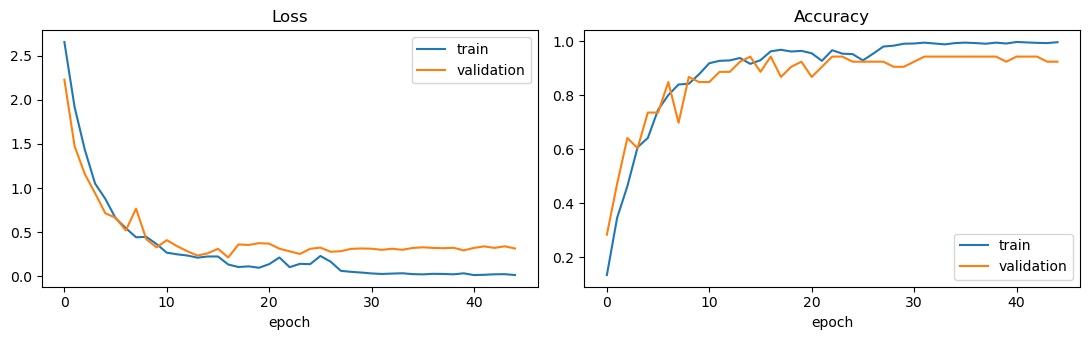

In [10]:
ckpt = MODELS / "isl_lstm_best.keras"
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=30, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5),
    keras.callbacks.ModelCheckpoint(ckpt, monitor="val_accuracy", save_best_only=True),
]
t0 = time.time()
hist = model.fit(X_aug, y_aug, validation_data=(X[va], y[va]), epochs=300, batch_size=32,
                 callbacks=callbacks, verbose=2)
print(f"training time {time.time() - t0:.0f} s | epochs run {len(hist.history['loss'])}")

h = hist.history
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="validation"); ax[1].set_title("Accuracy"); ax[1].legend()
for a_ in ax: a_.set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 5. Evaluate on the test split
The test videos were never used for training or for choosing the model.
**Caution:** the split is random by video, so test signers also appear in training; this accuracy is higher than it would be on new signers.

test accuracy 94.4% | macro F1 0.934 | majority-class baseline 7.4% | test videos 54
                precision    recall  f1-score   support

       alright       1.00      0.67      0.80         3
        animal       1.00      1.00      1.00         3
          bird       1.00      1.00      1.00         4
           cat       1.00      1.00      1.00         3
           cow       1.00      1.00      1.00         3
           dog       1.00      0.33      0.50         3
          fish       1.00      1.00      1.00         3
good afternoon       0.75      1.00      0.86         3
  good evening       0.75      1.00      0.86         3
  good morning       1.00      1.00      1.00         3
    good night       1.00      1.00      1.00         4
         hello       1.00      1.00      1.00         3
         horse       1.00      1.00      1.00         3
   how are you       1.00      1.00      1.00         4
         mouse       1.00      1.00      1.00         3
       pleased    

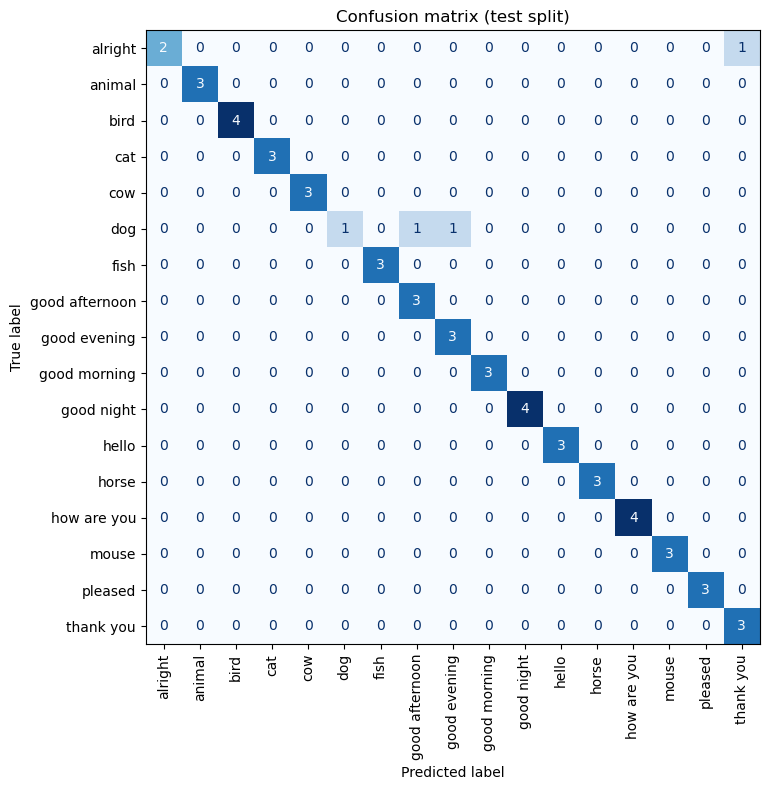

misclassified (true, predicted, confidence): [('dog', 'good evening', '0.62'), ('dog', 'good afternoon', '0.41'), ('alright', 'thank you', '0.61')]


In [11]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

probs = model.predict(X[te], verbose=0)
pred = probs.argmax(1)
acc = accuracy_score(y[te], pred)
f1 = f1_score(y[te], pred, average="macro")
baseline = np.bincount(y[te]).max() / te.sum()
print(f"test accuracy {acc:.1%} | macro F1 {f1:.3f} | majority-class baseline {baseline:.1%} | test videos {te.sum()}")
print(classification_report(y[te], pred, labels=range(len(classes)), target_names=classes, zero_division=0))

cm = confusion_matrix(y[te], pred, labels=range(len(classes)))
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, xticks_rotation=90, colorbar=False, cmap="Blues")
ax.set_title("Confusion matrix (test split)"); plt.tight_layout(); plt.show()

wrong = [(classes[t], classes[p_], f"{probs[i, p_]:.2f}") for i, (t, p_) in enumerate(zip(y[te], pred)) if t != p_]
print("misclassified (true, predicted, confidence):", wrong if wrong else "none")

## 6. Save the model and its settings
`realtime_demo.py` reads both files. The config records the class order and the window length, so the live system cannot silently use a different order.

In [12]:
model.save(MODELS / "isl_lstm.keras")
cfg = dict(classes=classes, T=P.T_FIXED, features="compact", n_features=int(X.shape[2]),
           window_sec=3.0, extract_fps=25, test_accuracy=round(float(acc), 4), test_macro_f1=round(float(f1), 4))
json.dump(cfg, open(MODELS / "isl_lstm_config.json", "w"), indent=2)

reloaded = keras.saving.load_model(MODELS / "isl_lstm.keras")          # check that the saved file really works
same = np.allclose(reloaded.predict(X[te][:5], verbose=0), model.predict(X[te][:5], verbose=0), atol=1e-5)
print("saved:", [p.name for p in MODELS.iterdir()], "| reloaded model gives the same output:", same)

saved: ['isl_lstm.keras', 'isl_lstm_best.keras', 'isl_lstm_config.json'] | reloaded model gives the same output: True


## 7. Optimisation: inference speed
The real-time loop calls the model many times per second, so the call method matters. `model.predict()` is built for large batches and has a high fixed cost per call; calling the model directly, or through a compiled `tf.function`, is much faster for one sample.
The second part times MediaPipe at model complexity 0 and 1 on one video.

In [13]:
x1 = X[te][:1]
infer = tf.function(lambda a: model(a, training=False), reduce_retracing=True)

def bench(fn, n=50):
    fn()                                           # warm-up, not timed
    ts = []
    for _ in range(n):
        t = time.perf_counter(); fn(); ts.append((time.perf_counter() - t) * 1000)
    return round(float(np.median(ts)), 2), round(float(np.percentile(ts, 95)), 2)

rows = []
for name, fn in [("model.predict(x)", lambda: model.predict(x1, verbose=0)),
                 ("model(x, training=False)", lambda: model(x1, training=False).numpy()),
                 ("tf.function (used in realtime_demo.py)", lambda: infer(tf.constant(x1)).numpy())]:
    med, p95 = bench(fn)
    rows.append(dict(method=name, median_ms=med, p95_ms=p95))
speed = pd.DataFrame(rows)
speed["speed-up vs predict"] = (speed.median_ms.iloc[0] / speed.median_ms).round(1)
speed

,method,median_ms,p95_ms,speed-up vs predict
0,model.predict(x),50.71,58.73,1.0
1,"model(x, training=False)",80.36,93.64,0.6
2,tf.function (used in realtime_demo.py),1.28,1.72,39.6


In [14]:
vid = meta.path.iloc[0]
rows = []
for c in (0, 1):
    t = time.perf_counter()
    s = P.extract_video_landmarks(vid, target_fps=25, model_complexity=c)
    dt = time.perf_counter() - t
    rows.append(dict(model_complexity=c, frames=len(s), seconds=round(dt, 2), frames_per_s=round(len(s) / dt, 1),
                     hand_rate=round(P.hand_rate(s), 3)))
pd.DataFrame(rows)

F:\anaconda\envs\isl-prep\lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


,model_complexity,frames,seconds,frames_per_s,hand_rate
0,0,117,6.54,17.9,0.906
1,1,117,5.13,22.8,0.915


## 8. End-to-end check from raw video
This re-runs the whole chain on test videos straight from the video files (extraction, preprocessing, model), the way `realtime_demo.py` does,
and compares it with the prediction from the cached Task 4 data. If the two disagree often, the live pipeline does not match training.

In [15]:
N_CHECK = 15                                        # number of test videos to re-extract (each takes a few seconds)
sub = meta[meta.split == "test"].head(N_CHECK)
rows = []
for i, r in sub.iterrows():
    try:
        s = P.extract_video_landmarks(r.path, target_fps=25)
        p_live = infer(P.preprocess(s)[None]).numpy()[0]
        p_cache = infer(X[i:i + 1]).numpy()[0]
        rows.append(dict(file=r.file, true=r.label, live=classes[p_live.argmax()], live_conf=round(float(p_live.max()), 2),
                         cached=classes[p_cache.argmax()], agree=p_live.argmax() == p_cache.argmax()))
    except Exception as e:                          # one bad video must not stop the check
        rows.append(dict(file=r.file, true=r.label, live=f"ERROR: {e}", live_conf=None, cached=None, agree=False))
e2e = pd.DataFrame(rows)
print(f"live vs cached agreement: {e2e.agree.mean():.0%} | live correct: {(e2e.live == e2e.true).mean():.0%} of {len(e2e)}")
e2e

F:\anaconda\envs\isl-prep\lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


live vs cached agreement: 100% | live correct: 87% of 15


,file,true,live,live_conf,cached,agree
0,MVI_3029.MOV,dog,dog,1.00,dog,True
1,MVI_8560.MP4,dog,good evening,0.62,good evening,True
2,MVI_8561.MP4,dog,good afternoon,0.41,good afternoon,True
3,MVI_3063.MOV,cat,cat,1.00,cat,True
4,MVI_3065.MOV,cat,cat,1.00,cat,True
5,MVI_3089.MOV,cat,cat,1.00,cat,True
6,MVI_3009.MOV,fish,fish,0.99,fish,True
7,MVI_3092.MOV,fish,fish,0.99,fish,True
8,MVI_3093.MOV,fish,fish,0.99,fish,True
9,MVI_3070.MOV,bird,bird,0.99,bird,True


## 9. Bug log (for the Task 5 report)
For each bug: a screenshot **before** (the error or wrong output), a screenshot **after** (fixed output), and one line of root cause.
Only list bugs you actually hit or reproduced. If you re-create an old error to screenshot it, say "reproduced".

| # | Symptom (before) | Root cause (one line) | Fix (after) |
|---|---|---|---|
| 1 | Scan showed 3 categories, one named "4. Bird" with 5 videos | Category was taken from `parent.parent`, which is wrong for videos one folder deeper | Category = first folder under the data root; sign = numbered folder (2 categories, 17 signs) |
| 2 | `ModuleNotFoundError: No module named 'cv2'` | Notebook ran on the base Python kernel, not the isl-prep environment | Select the "Python (isl-prep)" kernel |
| 3 | `EnvironmentNameNotFound: isl-prep` | The conda environment had never been created | `conda env create -f environment.yml` |
| 4 | `NameError: name 'scan_include' is not defined` | Helper functions lived in one cell and were lost after a kernel restart / new notebook | Moved into `isl_preprocess.py`, imported by every notebook and the live script |
| 5 | `resample()` on an empty clip: IndexError with no explanation | `np.linspace(0, -1, T)` gives negative indices when a video yields 0 frames | Clear `ValueError("empty sequence")`; the live loop skips windows with too few frames |
| 6 | (add any bug you hit while training or running the live demo) | | |

Code to reproduce bug 5 (before/after):

In [ ]:
def resample_old(seq, T=30):                        # Task 4 version, before the fix
    n = len(seq)
    pos = np.linspace(0, n - 1, T); i0 = np.floor(pos).astype(int); i1 = np.minimum(i0 + 1, n - 1); w = (pos - i0)[:, None]
    return (seq[i0] * (1 - w) + seq[i1] * w).astype(np.float32)

empty = np.zeros((0, 201), np.float32)
for name, fn in [("BEFORE", resample_old), ("AFTER", P.resample)]:
    try:
        fn(empty); print(name, "-> no error (wrong)")
    except Exception as e:
        print(f"{name} -> {type(e).__name__}: {e}")